# Student Behavior Clustering Analysis

This notebook segments students into behavioral clusters using K-Means clustering. We explore multiple feature sets to identify meaningful student personas for targeted interventions.

---
## 1. Setup & Data Loading <a id="1-setup"></a>

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

print("Libraries loaded.")

Libraries loaded.


In [2]:
# Configuration
PROC_DIR = Path("..") / "data" / "processed"
FIG_DIR = Path("..") / "data" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')

# Load the extended feature store
df = pd.read_csv(PROC_DIR / "ews_feature_store_extra.csv")
print(f"Feature store shape: {df.shape}")
print(f"Weeks: {df['week'].min()} to {df['week'].max()}")

# Aggregate to student-level (final snapshot)
KEY_COLS = ["student_id", "code_module", "code_presentation"]

student_final = (
    df.sort_values(KEY_COLS + ["week"])
    .groupby(KEY_COLS)
    .last()
    .reset_index()
)

print(f"\nStudent-level shape: {student_final.shape}")
print(f"Students: {student_final['student_id'].nunique():,}")

FileNotFoundError: [Errno 2] No such file or directory: '../data/processed/ews_feature_store_extra.csv'

---
## 2. Feature Set Definitions <a id="2-features"></a>

We define three clustering approaches, each capturing different aspects of student behavior:

| Feature Set | Features | Purpose |
|-------------|----------|--------|
| **Engagement** | cum_clicks_total, clicks_vs_cohort, days_since_last_activity, n_active_activity_types | Identify engagement levels with breadth of activity |
| **Engagement + Academic** | Above + cumulative_weighted_score_assess | Combine effort, breadth, and academic progress |
| **Trajectory** | delta_clicks_total, clicks_velocity, days_since_last_activity, avg_clicks_per_week | Capture momentum with time-normalized engagement |

### Feature Descriptions
- **cum_clicks_total**: Total cumulative clicks (engagement volume)
- **clicks_vs_cohort**: Relative engagement vs cohort average (peer comparison)
- **days_since_last_activity**: Recency of engagement (disengagement signal)
- **n_active_activity_types**: Number of different VLE activity types used (engagement breadth)
- **avg_clicks_per_week**: Time-normalized engagement (fair comparison across weeks)
- **delta_clicks_total**: Clicks in current week (recent activity)
- **clicks_velocity**: Week-over-week change in weekly clicks (acceleration/deceleration)

In [ ]:
# Define feature sets for clustering
FEATURE_SETS = {
    "engagement": {
        "features": ["cum_clicks_total", "clicks_vs_cohort", "days_since_last_activity"],
        "description": "Engagement intensity, recency, and breadth",
        "interpretation": {
            "high_clicks_low_recency": "Highly Engaged",
            "low_clicks_high_recency": "Disengaged/Dropout",
            "moderate": "Steady Learner"
        }
    },
    "engagement_academic": {
        "features": ["cum_clicks_total", "clicks_vs_cohort", "cumulative_weighted_score_assess", "days_since_last_activity"],
        "description": "Engagement + academic progress + breadth",
        "interpretation": {
            "high_both": "High Performer",
            "high_clicks_low_score": "Struggling Despite Effort",
            "low_clicks_high_score": "Efficient Learner",
            "low_both": "At Risk"
        }
    },
    "trajectory": {
        "features": ["delta_clicks_total", "clicks_velocity", "days_since_last_activity"],
        "description": "Behavioral momentum and time-normalized engagement",
        "interpretation": {
            "positive_velocity": "Improving/Accelerating",
            "negative_velocity": "Declining/Slowing Down",
            "stable": "Consistent"
        }
    }
}

# Display available features
print("Feature Sets Defined:")
for name, config in FEATURE_SETS.items():
    print(f"\n  {name}:")
    print(f"    Features: {config['features']}")
    print(f"    Purpose: {config['description']}")

Feature Sets Defined:

  engagement:
    Features: ['cum_clicks_total', 'clicks_vs_cohort', 'days_since_last_activity']
    Purpose: Engagement intensity, recency, and breadth

  engagement_academic:
    Features: ['cum_clicks_total', 'clicks_vs_cohort', 'cumulative_weighted_score_assess', 'days_since_last_activity']
    Purpose: Engagement + academic progress + breadth

  trajectory:
    Features: ['delta_clicks_total', 'clicks_velocity', 'days_since_last_activity']
    Purpose: Behavioral momentum and time-normalized engagement


In [ ]:
# Verify all features exist and show statistics
all_features = set()
for config in FEATURE_SETS.values():
    all_features.update(config["features"])

# Check for missing features
missing = [f for f in all_features if f not in student_final.columns]
if missing:
    print(f"WARNING: Missing features: {missing}")
    print("Run add_clustering_features.py to generate these features.")
else:
    print("All features available.")

print("\nFeature Statistics:")
print(student_final[list(all_features)].describe().round(2))

All features available.

Feature Statistics:
       cum_clicks_total  clicks_vs_cohort  clicks_velocity  \
count          28500.00          28500.00         28500.00   
mean            1388.81              0.66           -14.44   
std             1742.43              0.60           111.42   
min                1.00              0.00         -2059.00   
25%              287.00              0.28           -22.00   
50%              770.00              0.52            -3.00   
75%             1813.25              0.86             4.00   
max            24139.00             16.22          2594.00   

       delta_clicks_total  days_since_last_activity  \
count            28500.00                  28500.00   
mean                26.76                      2.89   
std                 79.86                      1.74   
min                  0.00                      0.00   
25%                  2.00                      1.00   
50%                  6.00                      3.00   
75%        

---
## 3. Clustering Analysis <a id="3-clustering"></a>

For each feature set:
1. Find optimal k using silhouette score
2. Fit K-Means with optimal k
3. Visualize clusters with PCA

In [ ]:
def find_optimal_k(X_scaled, k_range=range(3, 10)):
    """Find optimal k using silhouette score."""
    scores = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
        score = silhouette_score(X_scaled, labels)
        scores.append((k, score))
    return scores

def run_clustering(df, feature_set_name, features, k=None):
    """Run K-Means clustering on specified features."""
    # Prepare data
    X = df[features].fillna(0)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Find optimal k if not specified
    if k is None:
        scores = find_optimal_k(X_scaled)
        k = max(scores, key=lambda x: x[1])[0]
    
    # Fit model
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette = silhouette_score(X_scaled, labels)
    
    return {
        "labels": labels,
        "k": k,
        "silhouette": silhouette,
        "model": kmeans,
        "scaler": scaler,
        "X_scaled": X_scaled,
        "centroids": scaler.inverse_transform(kmeans.cluster_centers_)
    }

In [ ]:
# Run clustering for each feature set
results = {}

for name, config in FEATURE_SETS.items():
    print(f"\n{'='*60}")
    print(f"Feature Set: {name.upper()}")
    print(f"{'='*60}")
    print(f"Features: {config['features']}")
    
    # Find optimal k
    X = student_final[config['features']].fillna(0)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    scores = find_optimal_k(X_scaled)
    print(f"\nSilhouette scores by k:")
    for k, score in scores:
        print(f"  k={k}: {score:.4f}")
    
    # Run with optimal k
    result = run_clustering(student_final, name, config['features'])
    results[name] = result
    
    # Add labels to dataframe
    student_final[f'cluster_{name}'] = result['labels']
    
    print(f"\nOptimal k: {result['k']}")
    print(f"Silhouette score: {result['silhouette']:.4f}")
    print(f"\nCluster sizes:")
    print(student_final[f'cluster_{name}'].value_counts().sort_index())


Feature Set: ENGAGEMENT
Features: ['cum_clicks_total', 'clicks_vs_cohort', 'days_since_last_activity']

Silhouette scores by k:
  k=3: 0.3789
  k=4: 0.3833
  k=5: 0.3652
  k=6: 0.3465
  k=7: 0.3296
  k=8: 0.3231
  k=9: 0.3279

Optimal k: 4
Silhouette score: 0.3833

Cluster sizes:
cluster_engagement
0    12731
1      736
2     5128
3     9905
Name: count, dtype: int64

Feature Set: ENGAGEMENT_ACADEMIC
Features: ['cum_clicks_total', 'clicks_vs_cohort', 'cumulative_weighted_score_assess', 'days_since_last_activity']

Silhouette scores by k:
  k=3: 0.3010
  k=4: 0.2871
  k=5: 0.2972
  k=6: 0.3043
  k=7: 0.3143
  k=8: 0.3057
  k=9: 0.2958

Optimal k: 7
Silhouette score: 0.3143

Cluster sizes:
cluster_engagement_academic
0    4791
1    5400
2    1471
3    6631
4    6943
5     358
6    2906
Name: count, dtype: int64

Feature Set: TRAJECTORY
Features: ['delta_clicks_total', 'clicks_velocity', 'days_since_last_activity']

Silhouette scores by k:
  k=3: 0.4565
  k=4: 0.4824
  k=5: 0.4932
  k=6:

### 3.1 Cluster Visualizations

Saved: ../data/figures/clustering_pca_comparison.png


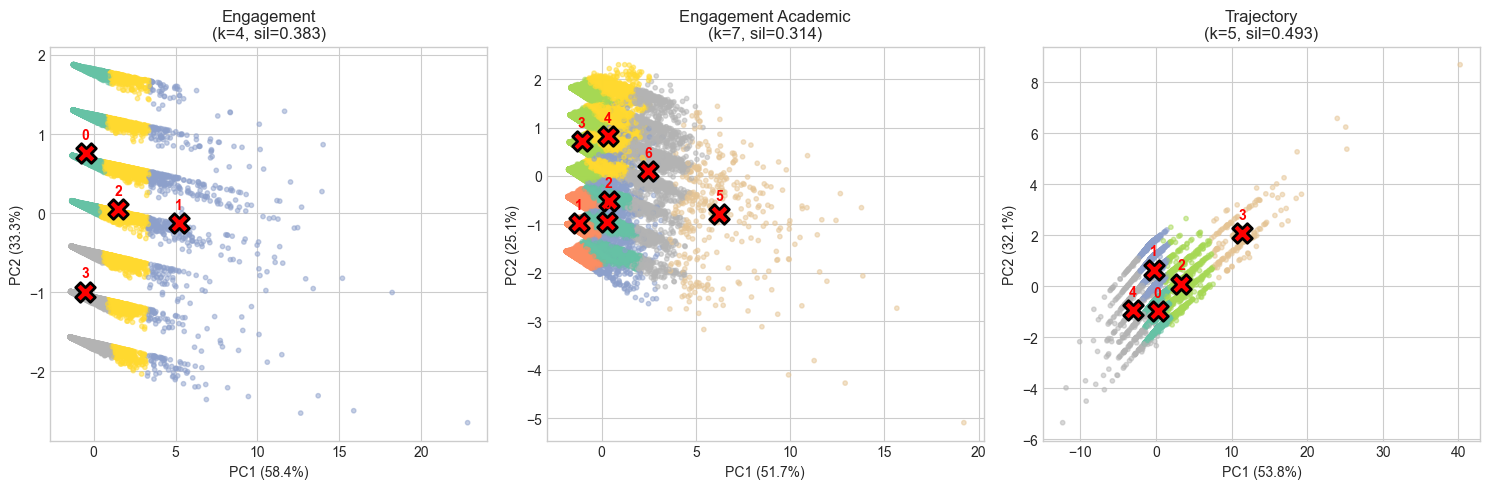

In [ ]:
# Visualize clusters for each feature set
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, (name, config) in enumerate(FEATURE_SETS.items()):
    ax = axes[idx]
    result = results[name]
    
    # PCA for visualization
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(result['X_scaled'])
    
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], 
                        c=result['labels'], cmap='Set2',
                        alpha=0.5, s=10)
    
    # Plot centroids
    centroids_pca = pca.transform(result['model'].cluster_centers_)
    ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
              c='red', marker='X', s=200, edgecolors='black', linewidths=2)
    
    # Add cluster number labels to centroids
    for cluster_num, (cx, cy) in enumerate(centroids_pca):
        ax.annotate(f'{cluster_num}', (cx, cy), fontsize=10, fontweight='bold',
                   ha='center', va='bottom', xytext=(0, 8), 
                   textcoords='offset points', color='red')
    
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.set_title(f'{name.replace("_", " ").title()}\n(k={result["k"]}, sil={result["silhouette"]:.3f})')

plt.tight_layout()
fig.savefig(FIG_DIR / "clustering_pca_comparison.png", dpi=150, bbox_inches="tight")
print(f"Saved: {FIG_DIR / 'clustering_pca_comparison.png'}")
plt.show()

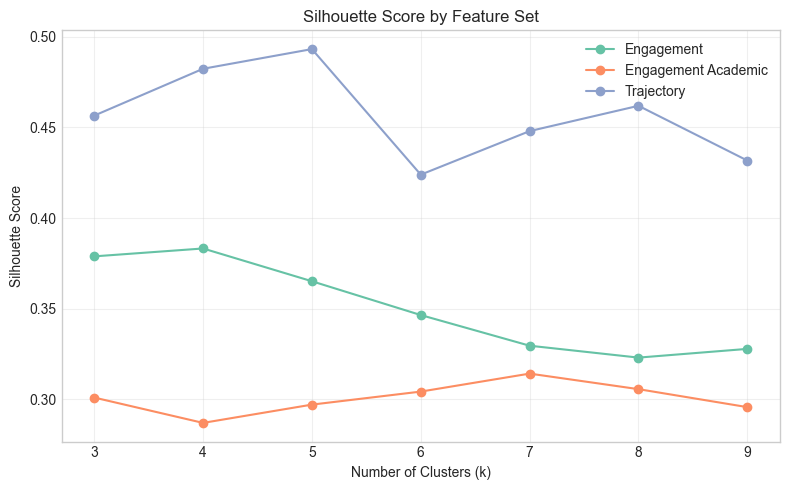

In [ ]:
# Plot silhouette comparison
fig, ax = plt.subplots(figsize=(8, 5))

for name, config in FEATURE_SETS.items():
    X = student_final[config['features']].fillna(0)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    scores = find_optimal_k(X_scaled)
    ks, sils = zip(*scores)
    ax.plot(ks, sils, marker='o', label=name.replace('_', ' ').title())

ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Silhouette Score')
ax.set_title('Silhouette Score by Feature Set')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Results & Interpretation <a id="4-results"></a>

### 4.1 Cluster Profiles by Feature Set

In [ ]:
# Configurable labeling rules - easy to extend or modify thresholds
LABELING_RULES = {
    "engagement": {
        "metrics": ["cum_clicks_total", "days_since_last_activity"],
        "rules": [
            # (label, condition_func) - checked in order, first match wins
            ("Highly Engaged", lambda row, overall, pct:
                row['cum_clicks_total'] > pct['cum_clicks_total_75'] and
                row['days_since_last_activity'] < pct['days_since_last_activity_50']),
            ("Disengaged/Dropout", lambda row, overall, pct:
                row['cum_clicks_total'] < pct['cum_clicks_total_25'] or
                row['days_since_last_activity'] > pct['days_since_last_activity_90']),
            ("Low Engagement", lambda row, overall, pct:
                row['cum_clicks_total'] < overall['cum_clicks_total']),
            ("Moderate Engagement", lambda row, overall, pct: True),  # default
        ]
    },
    "engagement_academic": {
        "metrics": ["cum_clicks_total", "cumulative_weighted_score_assess", "pass_rate"],
        "rules": [
            ("High Performer", lambda row, overall, pct:
                row['cum_clicks_total'] > overall['cum_clicks_total'] and
                row['cumulative_weighted_score_assess'] > overall['cumulative_weighted_score_assess']),
            ("Struggling Despite Effort", lambda row, overall, pct:
                row['cum_clicks_total'] > overall['cum_clicks_total'] and
                row['cumulative_weighted_score_assess'] < overall['cumulative_weighted_score_assess']),
            ("Efficient Learner", lambda row, overall, pct:
                row['cum_clicks_total'] <= overall['cum_clicks_total'] and
                row['cumulative_weighted_score_assess'] > overall['cumulative_weighted_score_assess']),
            ("At Risk (Likely Dropout)", lambda row, overall, pct:
                row['pass_rate'] < 0.3),
            ("Needs Support", lambda row, overall, pct: True),  # default
        ]
    },
    "trajectory": {
        "metrics": ["clicks_velocity", "days_since_last_activity"],
        "rules": [
            ("Accelerating", lambda row, overall, pct:
                row.get('clicks_velocity', 0) > 5),
            ("Gone Quiet", lambda row, overall, pct:
                row['days_since_last_activity'] > pct['days_since_last_activity_75']),
            ("Declining", lambda row, overall, pct:
                row.get('clicks_velocity', 0) < -5),
            ("Steady Pace", lambda row, overall, pct: True),  # default
        ]
    },
}

def compute_percentiles(df, cols, percentiles=[25, 50, 75, 90]):
    """Compute percentiles for given columns."""
    result = {}
    for col in cols:
        if col in df.columns:
            for p in percentiles:
                result[f'{col}_{p}'] = df[col].quantile(p / 100)
    return result

def assign_cluster_label(row, overall, percentiles, rules):
    """Apply labeling rules to a cluster row."""
    for label, condition in rules:
        try:
            if condition(row, overall, percentiles):
                return label
        except (KeyError, TypeError):
            continue
    return "Unknown"

def profile_clusters(df, cluster_col, features, feature_set_name):
    """Generate cluster profiles with interpretable labels."""

    # Calculate cluster statistics
    agg_dict = {
        'student_id': 'count',
        'cum_clicks_total': 'mean',
        'clicks_vs_cohort': 'mean',
        'cumulative_weighted_score_assess': 'mean',
        'days_since_last_activity': 'mean',
        'target_pass': 'mean'
    }
    # Add velocity for trajectory feature set
    if 'clicks_velocity' in df.columns:
        agg_dict['clicks_velocity'] = 'mean'

    stats = df.groupby(cluster_col).agg(agg_dict).rename(
        columns={'student_id': 'n_students', 'target_pass': 'pass_rate'}
    )

    # Overall averages for comparison
    overall = {
        'cum_clicks_total': df['cum_clicks_total'].mean(),
        'clicks_vs_cohort': df['clicks_vs_cohort'].mean(),
        'cumulative_weighted_score_assess': df['cumulative_weighted_score_assess'].mean(),
        'days_since_last_activity': df['days_since_last_activity'].mean(),
        'pass_rate': df['target_pass'].mean()
    }

    # Compute percentiles for data-driven thresholds
    percentile_cols = ['cum_clicks_total', 'days_since_last_activity', 'cumulative_weighted_score_assess']
    percentiles = compute_percentiles(df, percentile_cols)

    # Get labeling rules for this feature set (or use default)
    rules_config = LABELING_RULES.get(feature_set_name, {"rules": [("Cluster", lambda r, o, p: True)]})
    rules = rules_config["rules"]

    # Assign labels
    stats['label'] = [assign_cluster_label(row, overall, percentiles, rules)
                      for _, row in stats.iterrows()]

    return stats, overall

# Generate profiles for each feature set
profiles = {}
for name, config in FEATURE_SETS.items():
    cluster_col = f'cluster_{name}'
    stats, overall = profile_clusters(student_final, cluster_col, config['features'], name)
    profiles[name] = {'stats': stats, 'overall': overall}
    
    print(f"\n{'='*70}")
    print(f"FEATURE SET: {name.upper()}")
    print(f"{'='*70}")
    print(f"\nCluster Profiles:")
    print(stats.round(2).to_string())


FEATURE SET: ENGAGEMENT

Cluster Profiles:
                    n_students  cum_clicks_total  clicks_vs_cohort  cumulative_weighted_score_assess  days_since_last_activity  pass_rate  clicks_velocity                label
cluster_engagement                                                                                                                                                             
0                        12731            725.15              0.44                             39.20                      4.16       0.47           -16.86       Low Engagement
1                          736           7890.92              2.82                             75.55                      3.20       0.87           -39.74  Moderate Engagement
2                         5128           3349.57              1.24                             70.98                      3.11       0.83           -32.92  Moderate Engagement
3                         9905            743.56              0.48          

CLUSTER PROFILE VISUALIZATIONS

--- ENGAGEMENT ---
Saved: ../data/figures/clustering_engagement_profiles.png


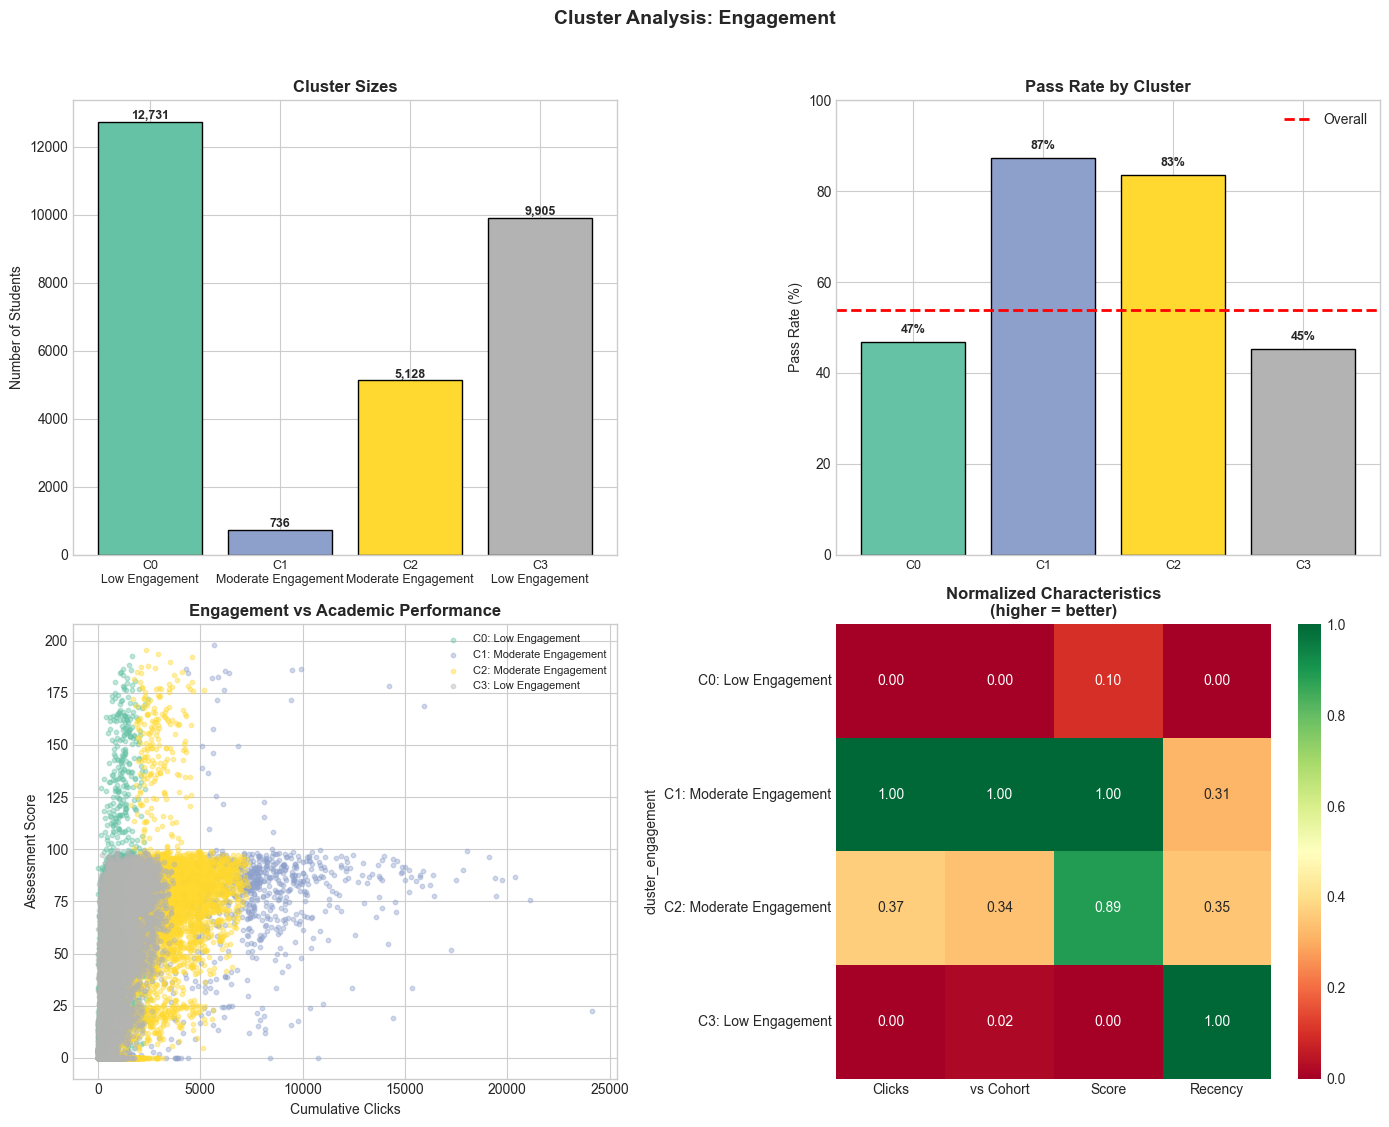


--- ENGAGEMENT_ACADEMIC ---
Saved: ../data/figures/clustering_engagement_academic_profiles.png


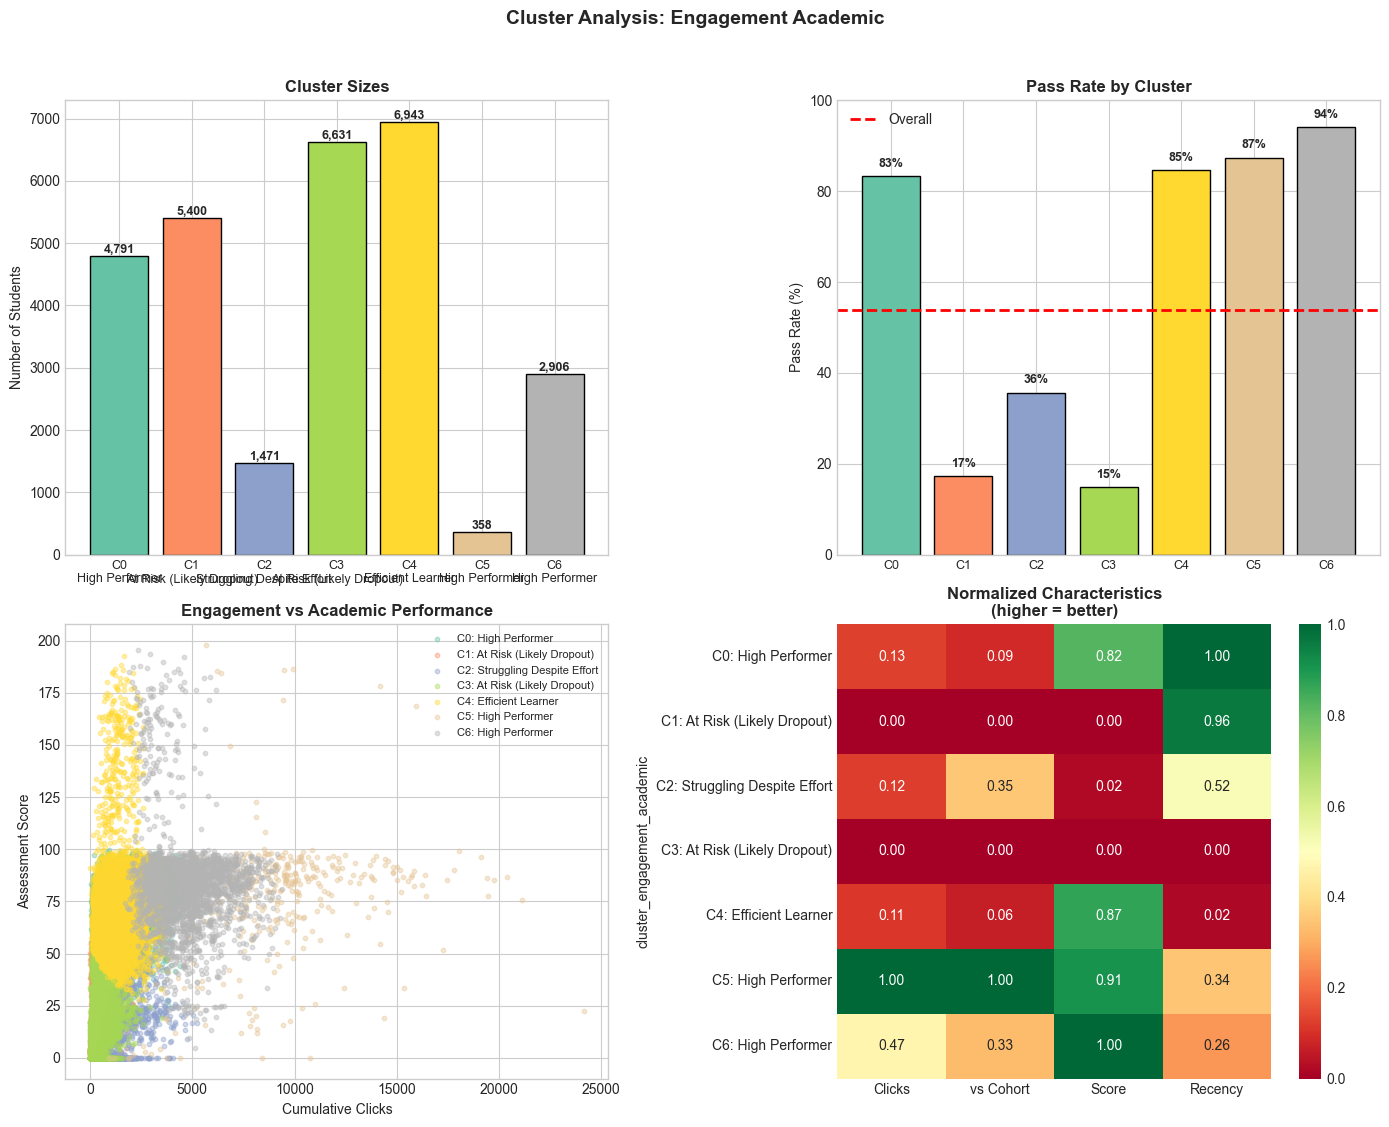


--- TRAJECTORY ---
Saved: ../data/figures/clustering_trajectory_profiles.png


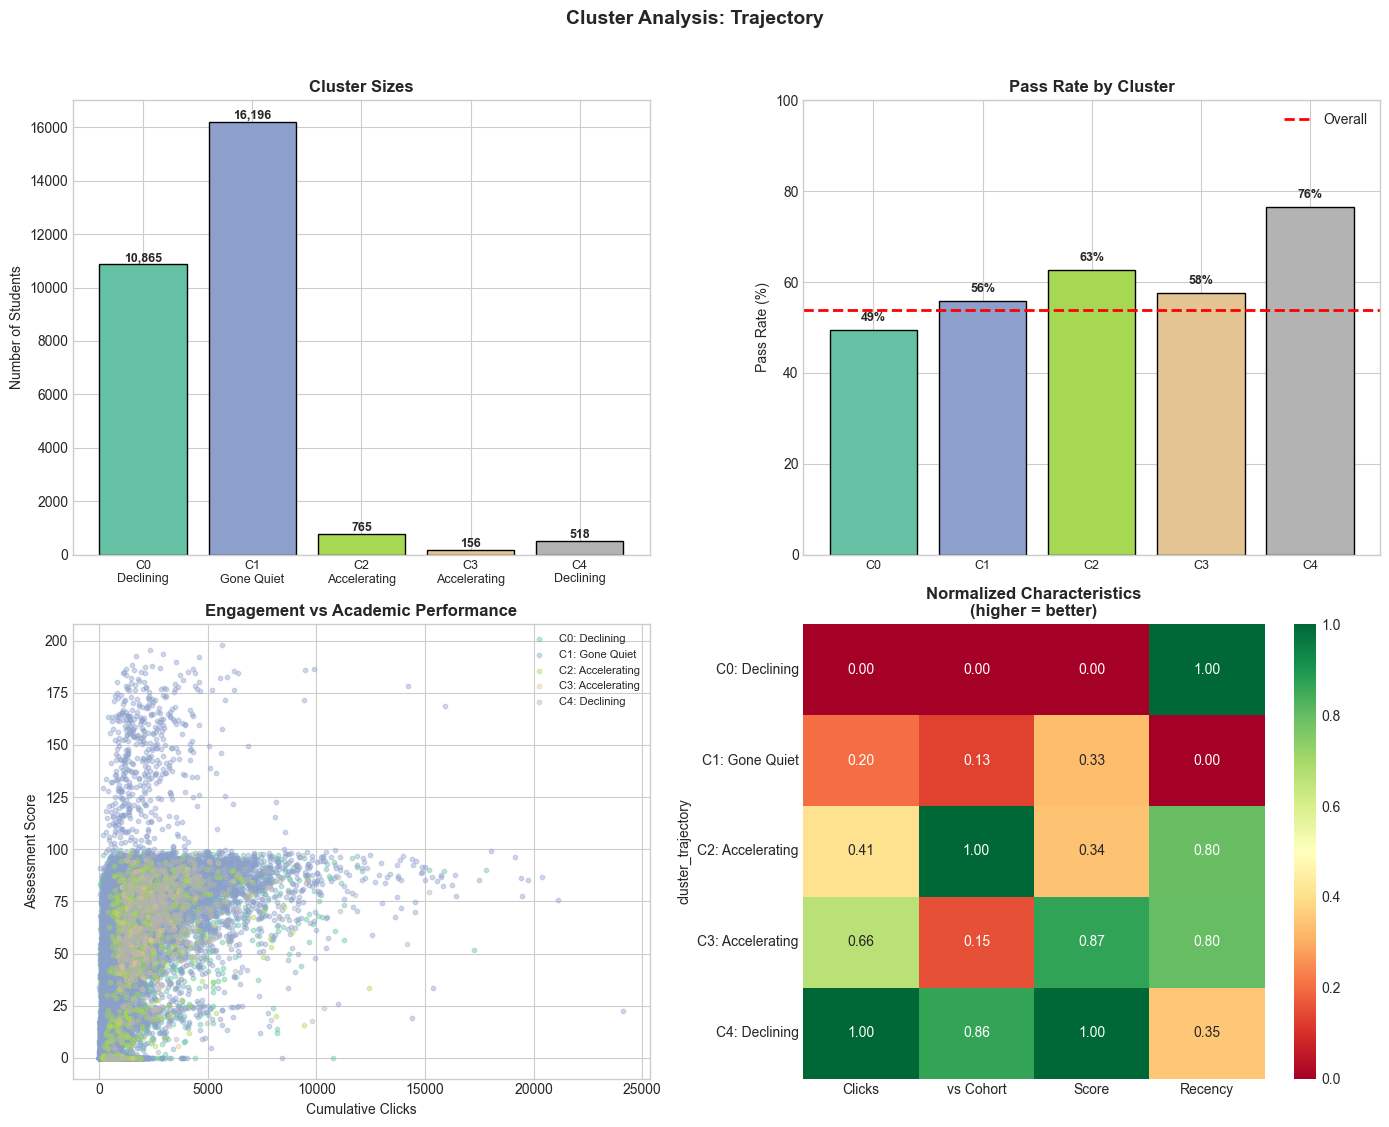

In [ ]:
def plot_cluster_profiles(feature_set_name, profiles_dict, student_df, fig_dir=None):
    """
    Visualize cluster profiles for a given feature set.
    
    Parameters:
    - feature_set_name: Name of the feature set (e.g., 'engagement', 'engagement_academic', 'trajectory')
    - profiles_dict: Dictionary containing 'stats' and 'overall' for this feature set
    - student_df: DataFrame with student data and cluster assignments
    - fig_dir: Optional directory to save figures
    """
    cluster_col = f"cluster_{feature_set_name}"
    stats = profiles_dict['stats']
    overall = profiles_dict['overall']
    n_clusters = len(stats)
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    colors = plt.cm.Set2(np.linspace(0, 1, n_clusters))
    
    # 1. Cluster sizes with labels
    ax = axes[0, 0]
    bars = ax.bar(range(n_clusters), stats['n_students'], color=colors, edgecolor='black')
    ax.set_xticks(range(n_clusters))
    ax.set_xticklabels([f"C{i}\n{stats.loc[i, 'label']}" for i in stats.index], fontsize=9)
    ax.set_ylabel('Number of Students')
    ax.set_title('Cluster Sizes', fontweight='bold')
    for bar, n in zip(bars, stats['n_students']):
        ax.annotate(f'{int(n):,}', (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    # 2. Pass rate by cluster
    ax = axes[0, 1]
    bars = ax.bar(range(n_clusters), stats['pass_rate'] * 100, color=colors, edgecolor='black')
    ax.axhline(y=overall['pass_rate'] * 100, color='red', linestyle='--', linewidth=2, label='Overall')
    ax.set_xticks(range(n_clusters))
    ax.set_xticklabels([f"C{i}" for i in stats.index], fontsize=9)
    ax.set_ylabel('Pass Rate (%)')
    ax.set_title('Pass Rate by Cluster', fontweight='bold')
    ax.legend()
    ax.set_ylim(0, 100)
    for bar, rate in zip(bars, stats['pass_rate']):
        ax.annotate(f'{rate:.0%}', (bar.get_x() + bar.get_width()/2, bar.get_height() + 2),
                    ha='center', fontsize=9, fontweight='bold')
    
    # 3. Engagement vs Score scatter
    ax = axes[1, 0]
    for cluster_id in sorted(student_df[cluster_col].unique()):
        subset = student_df[student_df[cluster_col] == cluster_id]
        ax.scatter(subset['cum_clicks_total'], subset['cumulative_weighted_score_assess'],
                  alpha=0.4, s=10, c=[colors[cluster_id]], 
                  label=f"C{cluster_id}: {stats.loc[cluster_id, 'label']}")
    ax.set_xlabel('Cumulative Clicks')
    ax.set_ylabel('Assessment Score')
    ax.set_title('Engagement vs Academic Performance', fontweight='bold')
    ax.legend(fontsize=8, loc='upper right')
    
    # 4. Cluster characteristics heatmap
    ax = axes[1, 1]
    heatmap_cols = ['cum_clicks_total', 'clicks_vs_cohort', 'cumulative_weighted_score_assess', 'days_since_last_activity']
    norm_stats = stats[heatmap_cols].copy()
    for col in norm_stats.columns:
        col_min, col_max = norm_stats[col].min(), norm_stats[col].max()
        norm_stats[col] = (norm_stats[col] - col_min) / (col_max - col_min + 1e-10)
    # Invert days_since_last_activity (lower is better)
    norm_stats['days_since_last_activity'] = 1 - norm_stats['days_since_last_activity']
    norm_stats.columns = ['Clicks', 'vs Cohort', 'Score', 'Recency']
    
    sns.heatmap(norm_stats, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax,
                yticklabels=[f"C{i}: {stats.loc[i, 'label']}" for i in stats.index])
    ax.set_title('Normalized Characteristics\n(higher = better)', fontweight='bold')
    
    title = feature_set_name.replace('_', ' ').title()
    plt.suptitle(f'Cluster Analysis: {title}', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    
    if fig_dir:
        filepath = fig_dir / f"clustering_{feature_set_name}_profiles.png"
        fig.savefig(filepath, dpi=150, bbox_inches="tight")
        print(f"Saved: {filepath}")
    
    plt.show()
    return fig

# Generate profile visualizations for all feature sets
print("="*70)
print("CLUSTER PROFILE VISUALIZATIONS")
print("="*70)

for name in FEATURE_SETS.keys():
    print(f"\n--- {name.upper()} ---")
    plot_cluster_profiles(name, profiles[name], student_final, FIG_DIR)

---
## 5. Key Insights for Instructors <a id="5-insights"></a>

This section provides actionable insights based on the **Engagement + Academic** clustering, which best captures both effort and outcomes.

In [ ]:
# Use the engagement_academic clustering for insights
cluster_col = "cluster_engagement_academic"
stats = profiles["engagement_academic"]['stats']
overall = profiles["engagement_academic"]['overall']

print("="*70)
print("KEY INSIGHTS FOR INSTRUCTORS")
print("="*70)

# Sort clusters by pass rate to identify risk levels
stats_sorted = stats.sort_values('pass_rate')

# 1. CRITICAL: Lowest pass rate cluster
critical_cluster = stats_sorted.index[0]
critical_stats = stats_sorted.iloc[0]
critical_students = student_final[student_final[cluster_col] == critical_cluster]

print(f"\n{'='*60}")
print("1. CRITICAL RISK GROUP")
print(f"{'='*60}")
print(f"   Cluster: {critical_cluster} ({critical_stats['label']})")
print(f"   Students: {int(critical_stats['n_students']):,} ({critical_stats['n_students']/len(student_final)*100:.1f}% of cohort)")
print(f"   Pass rate: {critical_stats['pass_rate']:.1%} (vs {overall['pass_rate']:.1%} overall)")
print(f"   Avg clicks: {critical_stats['cum_clicks_total']:,.0f} (vs {overall['cum_clicks_total']:,.0f} overall)")
print(f"   Avg score: {critical_stats['cumulative_weighted_score_assess']:.1f} (vs {overall['cumulative_weighted_score_assess']:.1f} overall)")
print(f"\n   RECOMMENDATION:")
print(f"   -> Immediate outreach required")
print(f"   -> Flag for academic advisor review")
print(f"   -> Consider phone/SMS contact for re-engagement")

# 2. HIGH PERFORMERS
best_cluster = stats_sorted.index[-1]
best_stats = stats_sorted.iloc[-1]

print(f"\n{'='*60}")
print("2. HIGH PERFORMERS (MODEL STUDENTS)")
print(f"{'='*60}")
print(f"   Cluster: {best_cluster} ({best_stats['label']})")
print(f"   Students: {int(best_stats['n_students']):,} ({best_stats['n_students']/len(student_final)*100:.1f}% of cohort)")
print(f"   Pass rate: {best_stats['pass_rate']:.1%}")
print(f"   Avg clicks: {best_stats['cum_clicks_total']:,.0f}")
print(f"   Avg score: {best_stats['cumulative_weighted_score_assess']:.1f}")
print(f"\n   RECOMMENDATION:")
print(f"   -> Potential peer mentors/tutors")
print(f"   -> Study their patterns to identify success behaviors")

# 3. HIGH EFFORT, LOW RESULTS (if exists)
struggling_clusters = stats[(stats['cum_clicks_total'] > overall['cum_clicks_total']) & 
                           (stats['cumulative_weighted_score_assess'] < overall['cumulative_weighted_score_assess'])]

if len(struggling_clusters) > 0:
    print(f"\n{'='*60}")
    print("3. HIGH EFFORT BUT STRUGGLING")
    print(f"{'='*60}")
    for idx, row in struggling_clusters.iterrows():
        print(f"   Cluster: {idx} ({row['label']})")
        print(f"   Students: {int(row['n_students']):,}")
        print(f"   Pass rate: {row['pass_rate']:.1%}")
        print(f"   Clicks: {row['cum_clicks_total']:,.0f} (above average)")
        print(f"   Score: {row['cumulative_weighted_score_assess']:.1f} (below average)")
    print(f"\n   RECOMMENDATION:")
    print(f"   -> These students are trying - they need academic support")
    print(f"   -> Offer tutoring or study skills workshops")
    print(f"   -> Review if content matches their learning style")

# 4. SUMMARY
print(f"\n{'='*60}")
print("4. INTERVENTION SUMMARY")
print(f"{'='*60}")
print(f"\n   Total students: {len(student_final):,}")
print(f"   Overall pass rate: {overall['pass_rate']:.1%}")

# Count students needing intervention (pass rate < 50%)
at_risk_clusters = stats[stats['pass_rate'] < 0.5]
at_risk_count = int(at_risk_clusters['n_students'].sum())
print(f"\n   Students in at-risk clusters (pass rate < 50%): {at_risk_count:,} ({at_risk_count/len(student_final)*100:.1f}%)")

print(f"\n   CLUSTER BREAKDOWN:")
for idx, row in stats_sorted.iterrows():
    risk = "CRITICAL" if row['pass_rate'] < 0.2 else "HIGH" if row['pass_rate'] < 0.5 else "MEDIUM" if row['pass_rate'] < 0.7 else "LOW"
    print(f"   -> Cluster {idx} ({row['label']}): {int(row['n_students']):,} students, {row['pass_rate']:.1%} pass rate [{risk} RISK]")

KEY INSIGHTS FOR INSTRUCTORS

1. CRITICAL RISK GROUP
   Cluster: 3 (At Risk (Likely Dropout))
   Students: 6,631 (23.3% of cohort)
   Pass rate: 14.9% (vs 54.0% overall)
   Avg clicks: 358 (vs 1,389 overall)
   Avg score: 10.8 (vs 44.4 overall)

   RECOMMENDATION:
   -> Immediate outreach required
   -> Flag for academic advisor review
   -> Consider phone/SMS contact for re-engagement

2. HIGH PERFORMERS (MODEL STUDENTS)
   Cluster: 6 (High Performer)
   Students: 2,906 (10.2% of cohort)
   Pass rate: 94.2%
   Avg clicks: 4,579
   Avg score: 83.2

   RECOMMENDATION:
   -> Potential peer mentors/tutors
   -> Study their patterns to identify success behaviors

3. HIGH EFFORT BUT STRUGGLING
   Cluster: 2 (Struggling Despite Effort)
   Students: 1,471
   Pass rate: 35.7%
   Clicks: 1,454 (above average)
   Score: 12.4 (below average)

   RECOMMENDATION:
   -> These students are trying - they need academic support
   -> Offer tutoring or study skills workshops
   -> Review if content match

In [ ]:
# Save clustered data for further analysis
output_cols = KEY_COLS + ['week', 'cum_clicks_total', 'clicks_vs_cohort', 'cumulative_weighted_score_assess',
                         'days_since_last_activity', 'target_pass', 'cluster_engagement', 
                         'cluster_engagement_academic', 'cluster_trajectory']

output_df = student_final[[c for c in output_cols if c in student_final.columns]]
output_path = PROC_DIR / "student_clusters.csv"
output_df.to_csv(output_path, index=False)
print(f"Saved clustered student data: {output_path}")
print(f"Shape: {output_df.shape}")

Saved clustered student data: ../data/processed/student_clusters.csv
Shape: (28500, 12)


---
## Summary

### Feature Sets Compared

| Feature Set | Best k | Silhouette | Best For |
|-------------|--------|------------|----------|
| Engagement | varies | varies | Identifying engagement levels |
| Engagement + Academic | varies | varies | Comprehensive student profiling |
| Trajectory | varies | varies | Detecting momentum changes |